# predict_mask: ฟังก์ชันแปลงภาพเป็น Binary Mask สำหรับฝั่ง IP

โมเดลแชมป์: **DeepLabV3+ (ResNet-50 ImageNet)** จาก Joint Training (IoU 55.12%, F1 68.84%)
รับภาพ BGR (numpy array) คืนค่า Binary Mask (0/255) ขนาดเท่าภาพต้นฉบับ เรียกฟังก์ชันเดียวจบ

In [1]:
import os, sys
os.chdir('/home/jovyan/cardashcam_train_model')
sys.path.append('.')

import cv2
import numpy as np
import torch
import segmentation_models_pytorch as smp

IMG_SIZE = (448, 800)  # (height, width) ขนาดที่โมเดลรับ ต้องตรงกับตอนเทรน

# ImageNet normalization
MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def load_model(checkpoint_path="models/joint_culane_thai_deeplabv3plus_resnet50_imagenet_best_f1.pth", device=None):
    """โหลดโมเดล DeepLabV3+ (ResNet-50 ImageNet) จาก checkpoint เรียกครั้งเดียวตอนเริ่มโปรแกรม"""
    if device is None:
        device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    else:
        device = torch.device(device)
    model = smp.DeepLabV3Plus(encoder_name="resnet50", encoder_weights=None,
                              in_channels=3, classes=1)
    obj = torch.load(checkpoint_path, map_location="cpu", weights_only=False)
    state_dict = obj["model_state_dict"] if isinstance(obj, dict) and "model_state_dict" in obj else obj
    model.load_state_dict(state_dict)
    model.to(device).eval()
    print(f"โหลดโมเดล DeepLabV3+ (ResNet-50 ImageNet) จาก {checkpoint_path} บน {device}")
    return model, device

@torch.inference_mode()
def predict_mask(model, frame, device=None, threshold=0.5):
    """
    รับภาพ 1 เฟรม (BGR, uint8) คืนค่า Binary Mask (0/255) ขนาดเท่าภาพต้นฉบับ

    Parameters
    ----------
    model : โมเดลจาก load_model()
    frame : numpy array (H, W, 3) BGR uint8
    device : torch.device (ถ้าไม่ระบุจะดูจากโมเดล)
    threshold : เกณฑ์ตัดสิน (ค่าเริ่มต้น 0.5)

    Returns
    -------
    numpy array (H, W) uint8 ค่า 0 หรือ 255
    """
    if device is None:
        device = next(model.parameters()).device
    orig_h, orig_w = frame.shape[:2]

    # 1. Resize เป็น 448x800
    resized = cv2.resize(frame, (IMG_SIZE[1], IMG_SIZE[0]), interpolation=cv2.INTER_LINEAR)

    # 2. BGR -> RGB -> float32 [0,1] -> Normalize ImageNet -> Tensor (1,C,H,W)
    rgb = cv2.cvtColor(resized, cv2.COLOR_BGR2RGB)
    tensor = torch.from_numpy(rgb).float().permute(2, 0, 1) / 255.0
    tensor = tensor.unsqueeze(0).to(device)
    tensor = (tensor - MEAN.to(device)) / STD.to(device)

    # 3. Forward pass + sigmoid + threshold
    logits = model(tensor)
    prob = torch.sigmoid(logits[0, 0]).cpu().numpy()
    mask_small = (prob > threshold).astype(np.uint8) * 255

    # 4. Resize กลับขนาดเดิม (NEAREST ไม่ให้ขอบเบลอ)
    mask = cv2.resize(mask_small, (orig_w, orig_h), interpolation=cv2.INTER_NEAREST)
    return mask


## ทดสอบ: โหลดโมเดลแล้วทำนาย 4 สภาพถนนจริง (Normal 1, Normal 2, Curve, Night)

In [2]:
import time

model, device = load_model()

# ตัวอย่าง 4 สภาพถนนหลักของประเทศไทย
test_samples = [
    ("ทางตรง 1 (Normal ชานเมือง)", "dataset/Thai_road_lane/images/normal__lumphaya_road02_0010.jpg"),
    ("ทางตรง 2 (Normal ในเมืองประตูน้ำ)", "dataset/Thai_road_lane/images/normal__Pratunam_road_0002.jpg"),
    ("ทางโค้ง (Curve อนุสาวรีย์ชัยฯ)", "dataset/Thai_road_lane/images/curve__Anusaowalee_curve01_0003.jpg"),
    ("เวลากลางคืน (Night สาทร)", "dataset/Thai_road_lane/images/night__sathon_road_night01_0013.jpg")
]

results = []
print("="*75)
print("🚗 ทดสอบ Inference โมเดล DeepLabV3+ (ResNet-50) บน 4 สภาพถนน")
print("="*75)

for label, img_path in test_samples:
    frame = cv2.imread(img_path)
    assert frame is not None, f"เปิดภาพไม่ได้: {img_path}"
    
    t0 = time.time()
    mask = predict_mask(model, frame, device)
    t1 = time.time()
    
    ms = (t1 - t0) * 1000
    lane_px = int((mask == 255).sum())
    print(f"[{label:30s}] ขนาด: {frame.shape[1]}x{frame.shape[0]} | เวลา: {ms:5.1f} ms | เส้นเลน: {lane_px:6,d} px")
    results.append((label, frame, mask, ms, lane_px))


โหลดโมเดล DeepLabV3+ (ResNet-50 ImageNet) จาก models/joint_culane_thai_deeplabv3plus_resnet50_imagenet_best_f1.pth บน cuda
🚗 ทดสอบ Inference โมเดล DeepLabV3+ (ResNet-50) บน 4 สภาพถนน
[ทางตรง 1 (Normal ชานเมือง)    ] ขนาด: 1920x1080 | เวลา: 179.5 ms | เส้นเลน: 29,422 px


[ทางตรง 2 (Normal ในเมืองประตูน้ำ)] ขนาด: 1920x1080 | เวลา:   9.6 ms | เส้นเลน: 25,732 px
[ทางโค้ง (Curve อนุสาวรีย์ชัยฯ)] ขนาด: 1920x1080 | เวลา:   9.8 ms | เส้นเลน: 29,907 px
[เวลากลางคืน (Night สาทร)      ] ขนาด: 1920x1080 | เวลา:  34.7 ms | เส้นเลน: 20,404 px


## แสดงผลเปรียบเทียบ 4 สภาพถนน: ภาพต้นฉบับ vs Binary Mask vs Mask ซ้อนทับ

✅ บันทึกภาพพล็อตเรียบร้อยที่: results/presentation_figures/predict_mask_4scenes_demo.png


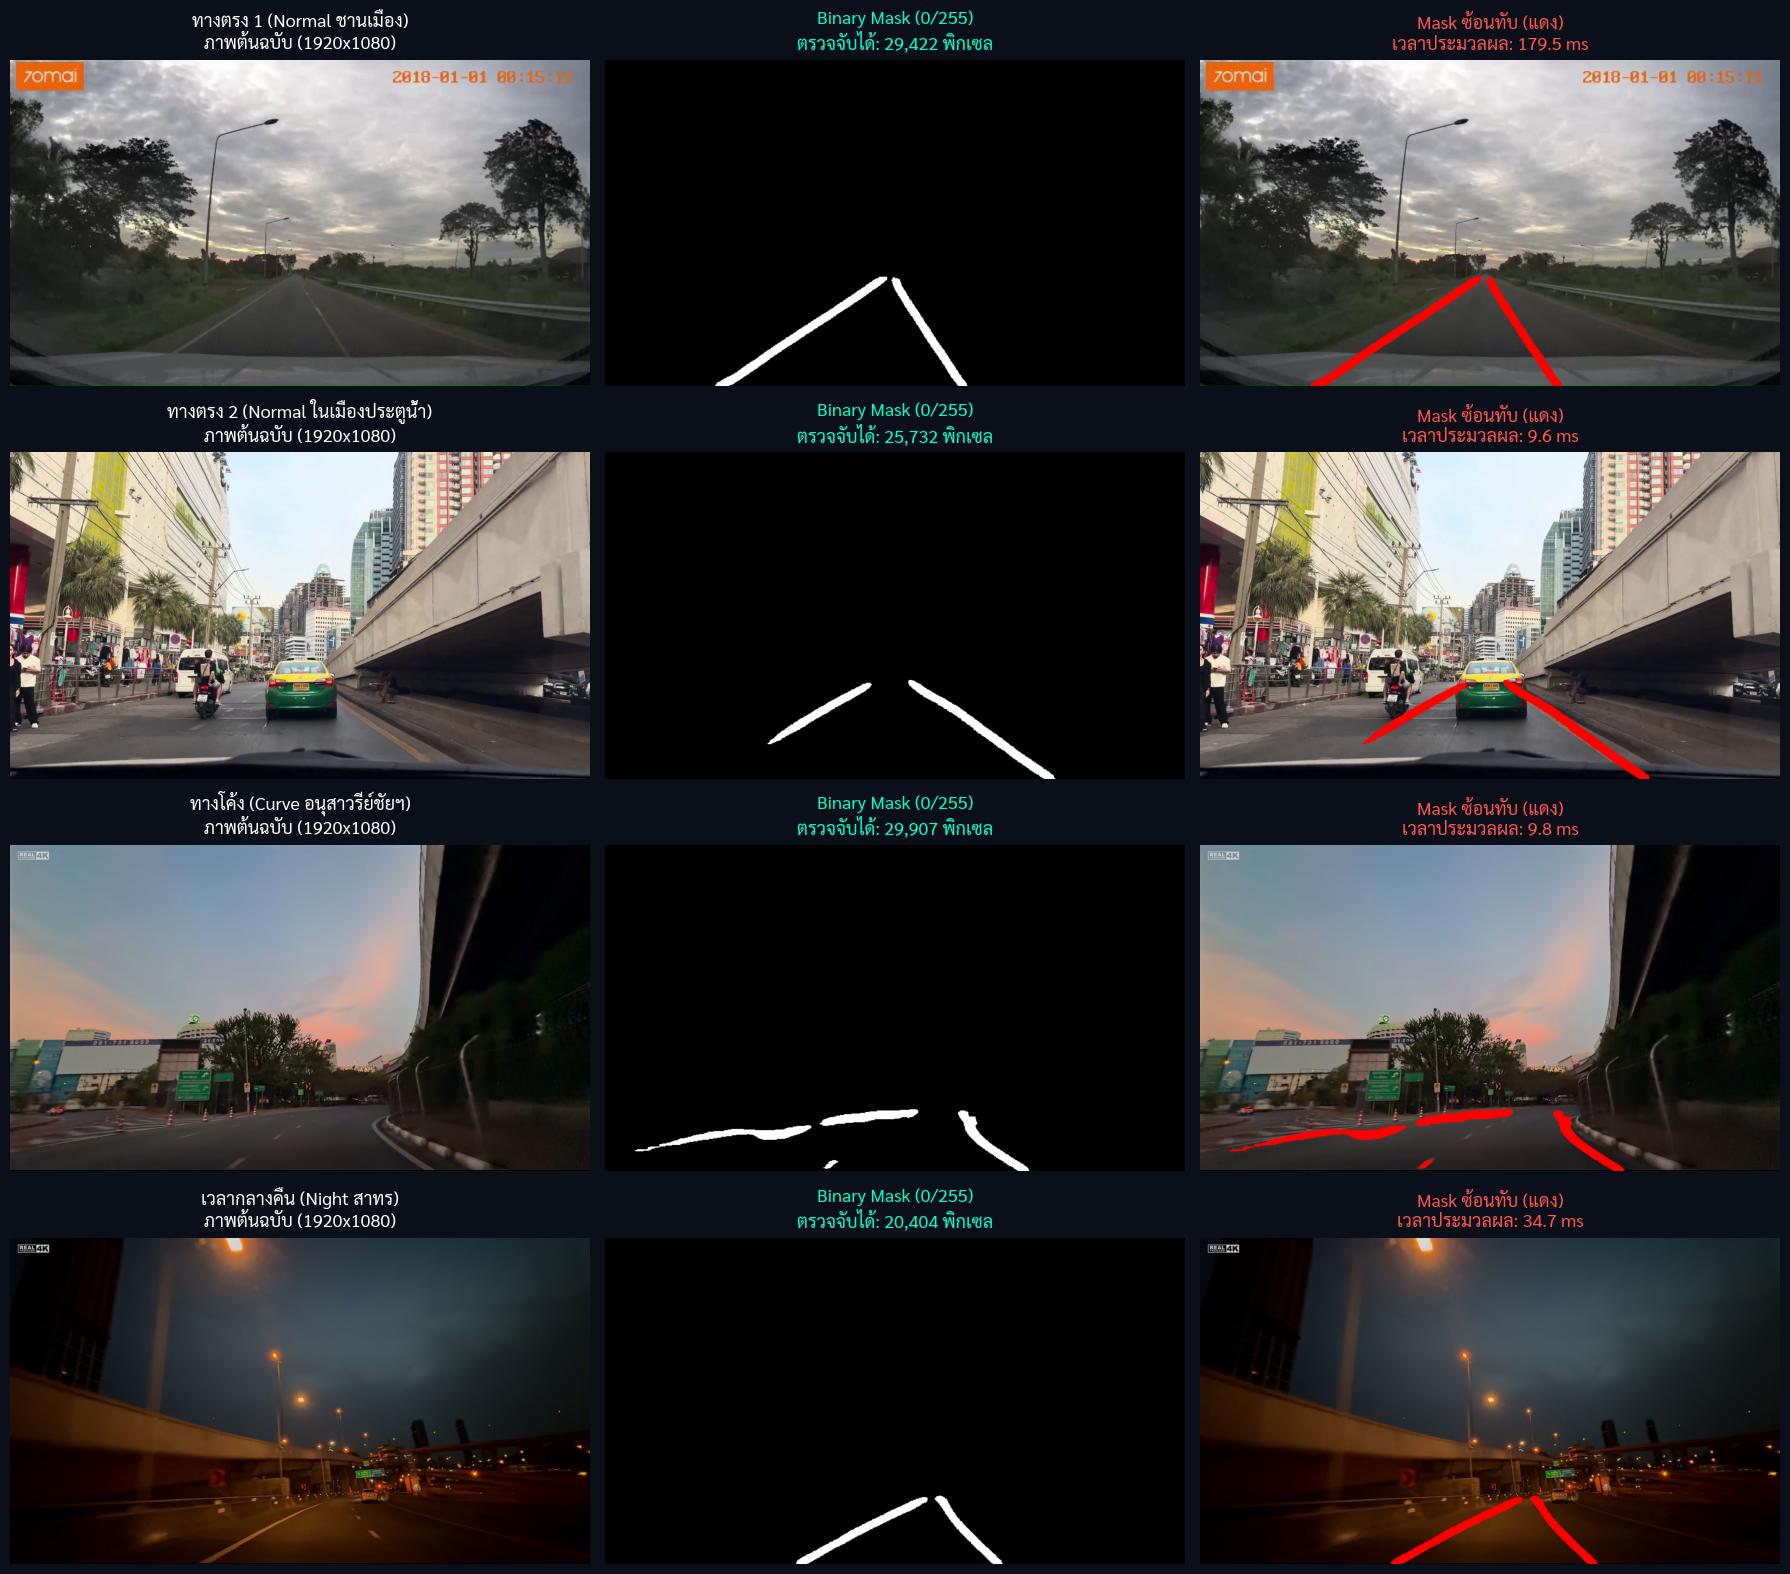

In [3]:
import matplotlib.pyplot as plt
from matplotlib import font_manager

font_p = "fonts/Sarabun-Regular.ttf"
sarabun = font_manager.FontProperties(fname=font_p) if os.path.exists(font_p) else None

fig, axes = plt.subplots(4, 3, figsize=(18, 16), facecolor="#0B0F19")

for i, (label, frame, mask, ms, lane_px) in enumerate(results):
    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    
    # 1. Original RGB
    axes[i, 0].imshow(rgb)
    title_1 = f"{label}\nภาพต้นฉบับ ({frame.shape[1]}x{frame.shape[0]})"
    axes[i, 0].set_title(title_1, fontproperties=sarabun, color="white", fontsize=13, pad=8)
    axes[i, 0].axis("off")
    
    # 2. Binary Mask
    axes[i, 1].imshow(mask, cmap="gray")
    title_2 = f"Binary Mask (0/255)\nตรวจจับได้: {lane_px:,} พิกเซล"
    axes[i, 1].set_title(title_2, fontproperties=sarabun, color="#00FFCC", fontsize=13, pad=8)
    axes[i, 1].axis("off")
    
    # 3. Mask ซ้อนทับ (แดง)
    overlay = rgb.copy()
    overlay[mask == 255] = [255, 0, 0]
    axes[i, 2].imshow(overlay)
    title_3 = f"Mask ซ้อนทับ (แดง)\nเวลาประมวลผล: {ms:.1f} ms"
    axes[i, 2].set_title(title_3, fontproperties=sarabun, color="#FF5555", fontsize=13, pad=8)
    axes[i, 2].axis("off")

plt.tight_layout()
demo_out = "results/presentation_figures/predict_mask_4scenes_demo.png"
plt.savefig(demo_out, dpi=180, bbox_inches="tight", facecolor=fig.get_facecolor())
plt.savefig("predict_mask_4scenes_demo.png", dpi=180, bbox_inches="tight", facecolor=fig.get_facecolor())
print(f"✅ บันทึกภาพพล็อตเรียบร้อยที่: {demo_out}")
plt.show()


## แปลง Binary Mask ทั้งหมด 191 ภาพ สำหรับชุดทดสอบทางการไทย (ส่งต่อฝั่ง IP)

In [4]:
import pandas as pd
from tqdm.auto import tqdm

test_csv = "dataset/Thai_road_lane/test_list.csv"
df_test = pd.read_csv(test_csv)
out_dir = "results/ip/pred_masks_dl"
os.makedirs(out_dir, exist_ok=True)

print(f"กำลังแปลงภาพทั้งหมด {len(df_test)} ภาพ เป็น Binary Mask ด้วย DeepLabV3+...")
for fname in tqdm(df_test["filename"]):
    img_p = os.path.join("dataset/Thai_road_lane/images", fname)
    f = cv2.imread(img_p)
    if f is None:
        continue
    m = predict_mask(model, f, device)
    out_name = os.path.splitext(fname)[0] + ".png"
    cv2.imwrite(os.path.join(out_dir, out_name), m)

print(f"✅ บันทึก Binary Mask ครบ {len(df_test)} ภาพ เรียบร้อยที่ {out_dir}")


กำลังแปลงภาพทั้งหมด 191 ภาพ เป็น Binary Mask ด้วย DeepLabV3+...


  0%|          | 0/191 [00:00<?, ?it/s]

✅ บันทึก Binary Mask ครบ 191 ภาพ เรียบร้อยที่ results/ip/pred_masks_dl
